In [ ]:

# TASK 9 - STEP 1: Environment and file check

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("ThreatLens Task 9")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nAvailable files:")

for path in glob.glob("/content/**/*", recursive=True):
    if os.path.isfile(path):
        print(os.path.basename(path))


ThreatLens Task 9
NumPy: 2.1.3
Pandas: 2.2.3

Available files:
ThreatLens_LSTM_Model.keras
ThreatLens_Logistic_Misclassifications.csv
ThreatLens_Task9_Decision_Results.csv
logistic_regression.joblib
ThreatLens_X_test.csv
ThreatLens_y_test.csv
ThreatLens_LSTM_Evaluation.csv
ThreatLens_Error_Pattern_Comparison.csv
random_forest.joblib
ThreatLens_Error_Summary.csv
ThreatLens_Model_Evaluation.csv
ThreatLens_DecisionTree_Misclassifications.csv
ThreatLens_X_train.csv
decision_tree.joblib
ThreatLens_LSTM_Predictions.csv
ThreatLens_RandomForest_Misclassifications.csv
ThreatLens_Feature_Importance.csv
ThreatLens_Task9_Model_Comparison.csv
ThreatLens_Task9_Final_Report.csv
ThreatLens_y_train.csv
README.md
anscombe.json
california_housing_test.csv
mnist_test.csv
mnist_train_small.csv
california_housing_train.csv


Load the training and testing datasets

In [ ]:

# TASK 9 - STEP 2: Load datasets

from pathlib import Path

DATA_DIR = Path("/content")

def find_file(pattern):
    matches = list(DATA_DIR.glob(pattern))
    if not matches:
        raise FileNotFoundError(
            f"Cannot find {pattern}. Check the Colab Files panel."
        )
    return matches[0]

X_train = pd.read_csv(find_file("ThreatLens_X_train.csv"))
X_test  = pd.read_csv(find_file("ThreatLens_X_test.csv"))
y_train = pd.read_csv(find_file("ThreatLens_y_train.csv"))
y_test  = pd.read_csv(find_file("ThreatLens_y_test.csv"))

# Remove accidental CSV index columns
def clean_index_columns(df):
    return df.loc[
        :,
        ~df.columns.str.match(r"^(Unnamed:.*|index|level_0)$",
                              case=False)
    ].copy()

X_train = clean_index_columns(X_train)
X_test = clean_index_columns(X_test)
y_train = clean_index_columns(y_train)
y_test = clean_index_columns(y_test)

# Targets should contain one column
if y_train.shape[1] != 1 or y_test.shape[1] != 1:
    raise ValueError("Expected one target column in each y CSV.")

y_train = y_train.iloc[:, 0].reset_index(drop=True)
y_test = y_test.iloc[:, 0].reset_index(drop=True)

# Match the testing feature order to the training feature order
if set(X_train.columns) != set(X_test.columns):
    raise ValueError("Training and testing features do not match.")

X_test = X_test[X_train.columns]

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Target classes   :", sorted(y_train.unique().tolist()))
print("\nFirst five feature names:")
print(X_train.columns[:5].tolist())


Training features: (1785444, 20)
Testing features : (446362, 20)
Target classes   : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

First five feature names:
['numeric__Avg Packet Size', 'numeric__Bwd Packet Length Mean', 'numeric__Avg Bwd Segment Size', 'numeric__Subflow Bwd Bytes', 'numeric__Bwd Packets Length Total']


Load the trained LSTM

In [ ]:

# TASK 9 - STEP 3: Load deep learning model

from tensorflow.keras.models import load_model

lstm_path = find_file("ThreatLens_LSTM_Model.keras")
lstm_model = load_model(lstm_path)

print("Loaded:", lstm_path.name)
print("Expected LSTM input shape:", lstm_model.input_shape)
print("Model output shape:", lstm_model.output_shape)

lstm_model.summary()


Loaded: ThreatLens_LSTM_Model.keras
Expected LSTM input shape: (None, 1, 20)
Model output shape: (None, 15)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        21,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73,007 (285.19 KB)

 Trainable params: 24,335 (95.06 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 48,672 (190.13 KB)

Prepare the input for all models

In [ ]:

# TASK 9 - STEP 4: Prepare LSTM input

X_train_np = X_train.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

input_shape = lstm_model.input_shape

if isinstance(input_shape, list):
    raise ValueError("This code expects a single-input LSTM model.")

if len(input_shape) == 3:
    timesteps = input_shape[1]
    expected_features = input_shape[2]

    if timesteps is None or expected_features is None:
        raise ValueError(
            "The model has dynamic input dimensions. "
            "Inspect its architecture before reshaping."
        )

    if X_train_np.shape[1] != timesteps * expected_features:
        raise ValueError(
            f"Dataset has {X_train_np.shape[1]} features, but the "
            f"LSTM expects {timesteps} x {expected_features}. "
            "Use the exact preprocessing and reshape used in Task 7."
        )

    X_train_lstm = X_train_np.reshape(
        len(X_train_np), timesteps, expected_features
    )
    X_test_lstm = X_test_np.reshape(
        len(X_test_np), timesteps, expected_features
    )

elif len(input_shape) == 2:
    X_train_lstm = X_train_np
    X_test_lstm = X_test_np

else:
    raise ValueError(f"Unsupported input shape: {input_shape}")

print("ML input:", X_train_np.shape, X_test_np.shape)
print("LSTM input:", X_train_lstm.shape, X_test_lstm.shape)


ML input: (1785444, 20) (446362, 20)
LSTM input: (1785444, 1, 20) (446362, 1, 20)


Integrate the three Machine Learning models


In [ ]:

# TASK 9 - STEP 5: Train and integrate ML classifiers

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

ml_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

for name, model in ml_models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully.")

# Save models for reuse
for name, model in ml_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, f"/content/{filename}")

print("\nAll ML models are ready.")


Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.

All ML models are ready.


Generate predictions from ML and DL

In [ ]:

# TASK 9 - STEP 6: Run all models

ml_predictions = {}

for name, model in ml_models.items():
    ml_predictions[name] = model.predict(X_test)

# LSTM predictions
lstm_probabilities = lstm_model.predict(
    X_test_lstm, verbose=0
)

if lstm_probabilities.ndim == 1:
    lstm_probabilities = lstm_probabilities.reshape(-1, 1)

if lstm_probabilities.shape[1] == 1:
    # Binary classification: assumes 0/1 encoded targets
    lstm_predictions = (
        lstm_probabilities.ravel() >= 0.5
    ).astype(int)
else:
    # Multiclass classification: assumes encoded target classes
    lstm_predictions = np.argmax(
        lstm_probabilities, axis=1
    )

print("ML and LSTM predictions generated.")

print("\nFirst 10 Random Forest predictions:")
print(ml_predictions["Random Forest"][:10])

print("\nFirst 10 LSTM predictions:")
print(lstm_predictions[:10])


ML and LSTM predictions generated.

First 10 Random Forest predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 LSTM predictions:
[0 0 0 0 0 0 0 0 0 0]


Evaluate and compare model performance

In [ ]:

# TASK 9 - STEP 7: Compare model performance

results = []

all_predictions = {
    **ml_predictions,
    "LSTM": lstm_predictions
}

for name, predictions in all_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "/content/ThreatLens_Task9_Model_Comparison.csv",
    index=False
)
print("\nSaved model comparison CSV.")


              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9574     0.9520  0.9574    0.9515
      Decision Tree    0.9984     0.9984  0.9984    0.9984
      Random Forest    0.9986     0.9985  0.9986    0.9985
               LSTM    0.9916     0.9913  0.9916    0.9909

Saved model comparison CSV.


Performance visualization

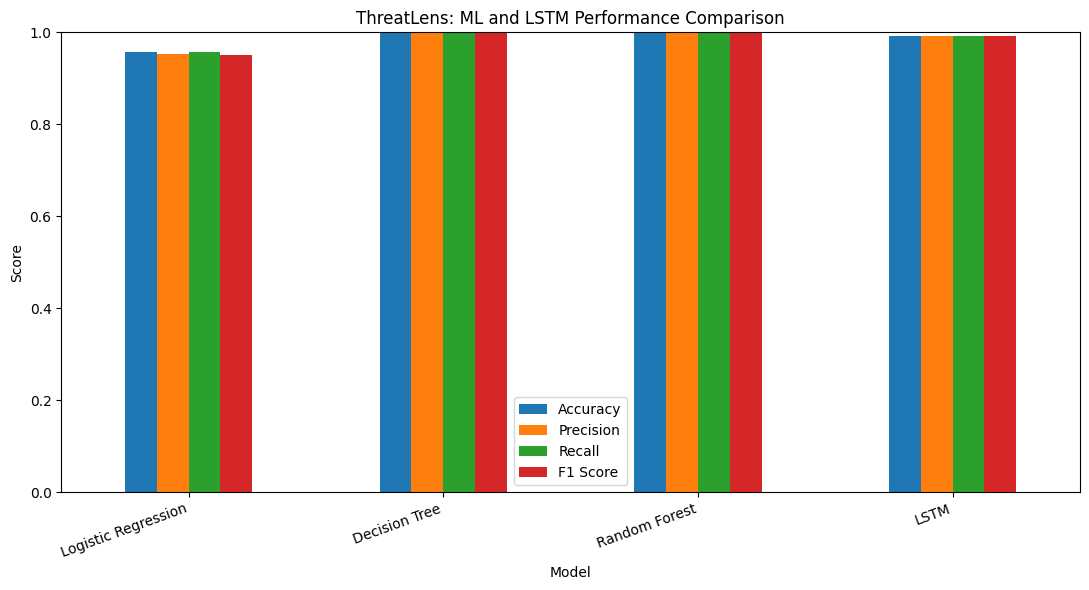

In [ ]:

# TASK 9 - STEP 7A: Performance visualization

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(11, 6), ylim=(0, 1)
)

plt.title("ThreatLens: ML and LSTM Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


Build the AI rule-based expert system

In [ ]:

# TASK 9 - STEP 8: AI rule-based starter engine

# Calculate feature thresholds from TRAINING data only.
# This avoids using test data to establish thresholds.

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

rule_thresholds = {}

for feature in numeric_features:
    median = X_train[feature].median()
    q1 = X_train[feature].quantile(0.25)
    q3 = X_train[feature].quantile(0.75)
    iqr = q3 - q1

    rule_thresholds[feature] = median + 3 * iqr

def apply_ai_rules(row):
    matched_rules = []

    for feature, threshold in rule_thresholds.items():
        value = row[feature]

        if pd.notna(value) and value > threshold:
            matched_rules.append(
                f"R-OUTLIER: {feature}={value:.4g} "
                f"exceeds training threshold {threshold:.4g}"
            )

    if matched_rules:
        return {
            "rule_flag": True,
            "rule_evidence": "; ".join(matched_rules)
        }

    return {
        "rule_flag": False,
        "rule_evidence": "No configured outlier rule matched"
    }

rule_results = pd.DataFrame(
    [apply_ai_rules(row) for _, row in X_test.iterrows()]
)

print(rule_results.head(10).to_string(index=False))


 rule_flag                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       rule_ev

Integrate AI, ML and DL into one decision engine

In [ ]:

# TASK 9 - STEP 9: Intelligent decision fusion

from collections import Counter

def make_decision(index):
    votes = {
        model_name: predictions[index]
        for model_name, predictions in all_predictions.items()
    }

    vote_counts = Counter(votes.values())
    highest_count = max(vote_counts.values())

    # Do not arbitrarily select a class if the vote is tied
    winners = [
        label for label, count in vote_counts.items()
        if count == highest_count
    ]

    consensus = winners[0] if len(winners) == 1 else None
    agreement = highest_count / len(votes)

    rule_flag = bool(rule_results.iloc[index]["rule_flag"])
    rule_evidence = rule_results.iloc[index]["rule_evidence"]

    if consensus is None:
        final_status = "Model disagreement - investigate"
    elif rule_flag:
        final_status = "Rule alert - investigate"
    elif agreement < 0.75:
        final_status = "Low agreement - investigate"
    else:
        final_status = "Model consensus - review predicted class"

    explanation = (
        f"Predictions: {votes}. "
        f"Agreement: {agreement:.0%}. "
        f"AI rule evidence: {rule_evidence}."
    )

    return {
        "Predicted_Class": consensus,
        "Model_Agreement": round(agreement, 3),
        "Rule_Triggered": rule_flag,
        "Rule_Evidence": rule_evidence,
        "Decision_Status": final_status,
        "Explanation": explanation
    }

decision_rows = [
    make_decision(i) for i in range(len(X_test))
]

decisions_df = pd.DataFrame(decision_rows)

print(decisions_df.head(10).to_string(index=False))


 Predicted_Class  Model_Agreement  Rule_Triggered                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

Add recommended actions

In [ ]:

# TASK 9 - STEP 10: Explainable recommendations

def recommend_action(row):
    status = row["Decision_Status"]

    if "disagreement" in status.lower():
        return (
            "Review the original log and compare model outputs. "
            "Escalate for analyst review if suspicious."
        )

    if "rule alert" in status.lower():
        return (
            "Inspect the rule-triggering fields and verify the event "
            "against source logs before taking action."
        )

    if "low agreement" in status.lower():
        return (
            "Review the event and validate it against additional "
            "security evidence."
        )

    return (
        "Review the predicted class and supporting evidence. "
        "Do not treat model consensus alone as proof of safety."
    )

decisions_df["Recommended_Action"] = decisions_df.apply(
    recommend_action, axis=1
)

print(
    decisions_df[
        [
            "Predicted_Class",
            "Decision_Status",
            "Recommended_Action"
        ]
    ].head(10).to_string(index=False)
)


 Predicted_Class                          Decision_Status                                                                                         Recommended_Action
             0.0                 Rule alert - investigate          Inspect the rule-triggering fields and verify the event against source logs before taking action.
             0.0 Model consensus - review predicted class Review the predicted class and supporting evidence. Do not treat model consensus alone as proof of safety.
             0.0                 Rule alert - investigate          Inspect the rule-triggering fields and verify the event against source logs before taking action.
             0.0                 Rule alert - investigate          Inspect the rule-triggering fields and verify the event against source logs before taking action.
             0.0                 Rule alert - investigate          Inspect the rule-triggering fields and verify the event against source logs before taking action.
          

Generate the final output CSV

In [ ]:

# TASK 9 - STEP 11: Create final report

final_report = X_test.reset_index(drop=True).copy()

final_report["Actual_Class"] = y_test.reset_index(drop=True)

for model_name, predictions in all_predictions.items():
    safe_name = model_name.replace(" ", "_")
    final_report[f"{safe_name}_Prediction"] = predictions

final_report = pd.concat(
    [final_report, decisions_df.reset_index(drop=True)],
    axis=1
)

output_path = "/content/ThreatLens_Task9_Final_Report.csv"

final_report.to_csv(output_path, index=False)

print("Final report saved to:", output_path)
print("Total records processed:", len(final_report))
print("\nDecision summary:")
print(final_report["Decision_Status"].value_counts())


Final report saved to: /content/ThreatLens_Task9_Final_Report.csv
Total records processed: 446362

Decision summary:
Decision_Status
Model consensus - review predicted class    256790
Rule alert - investigate                    186448
Model disagreement - investigate              3117
Low agreement - investigate                      7
Name: count, dtype: int64


Visualize the final decisions

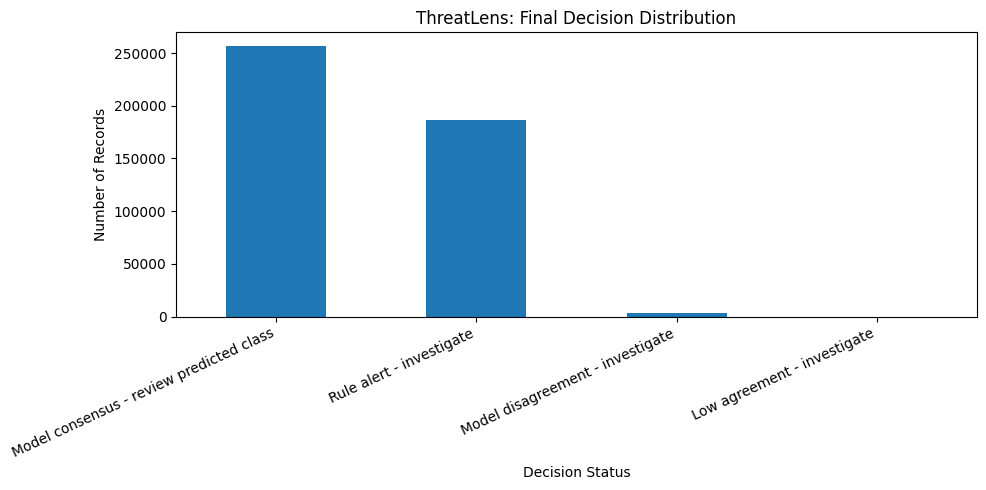

In [ ]:

# TASK 9 - STEP 12: Decision distribution chart

decision_counts = decisions_df["Decision_Status"].value_counts()

plt.figure(figsize=(10, 5))
decision_counts.plot(kind="bar")

plt.title("ThreatLens: Final Decision Distribution")
plt.xlabel("Decision Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


Check the final model performance

In [ ]:

# TASK 9 - STEP 13: Detailed classification reports

for model_name, predictions in all_predictions.items():
    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))



Logistic Regression
              precision    recall  f1-score   support

           0       0.96      1.00      0.98    379064
           1       1.00      0.01      0.02       288
           2       0.96      0.64      0.77     25603
           3       0.77      0.68      0.72      2057
           4       1.00      0.89      0.94     34569
           5       0.19      0.06      0.09      1046
           6       0.83      0.31      0.46      1077
           7       0.00      0.00      0.00      1186
           8       0.50      0.50      0.50         2
           9       0.00      0.00      0.00         7
          10       0.00      0.00      0.00       391
          11       0.80      0.54      0.65       644
          12       0.00      0.00      0.00       294
          13       0.00      0.00      0.00         4
          14       0.00      0.00      0.00       130

    accuracy                           0.96    446362
   macro avg       0.47      0.31      0.34    446362
weigh

Save the complete model comparison

In [ ]:

# TASK 9 - STEP 14: Save all Task 9 outputs

results_df.to_csv(
    "/content/ThreatLens_Task9_Model_Comparison.csv",
    index=False
)

decisions_df.to_csv(
    "/content/ThreatLens_Task9_Decision_Results.csv",
    index=False
)

print("Task 9 output files created:")
print("1. ThreatLens_Task9_Model_Comparison.csv")
print("2. ThreatLens_Task9_Decision_Results.csv")
print("3. ThreatLens_Task9_Final_Report.csv")


Task 9 output files created:
1. ThreatLens_Task9_Model_Comparison.csv
2. ThreatLens_Task9_Decision_Results.csv
3. ThreatLens_Task9_Final_Report.csv


TASK 10